<a href="https://colab.research.google.com/github/sania0507/Exploring-Data-Analysis/blob/main/DVA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DVA Laboratory - Experiments 1 to 7
**Google Colab notebook** - every step is one cell, so each output appears under its own step.

**Datasets used**

| Exp | Dataset | How to get it |
|---|---|---|
| 1 | `CARS.csv` | Kaggle `ljanjughazyan/cars1` -> upload |
| 2 | `california_housing_train.csv` | already in Colab `/content/sample_data/` |
| 3 | `datasetforexp3_hotel_booking.csv` | upload (Kaggle hotel booking demand) |
| 4 | `DailyDelhiClimateTrain.csv` | Kaggle `sumanthvrao/daily-climate-time-series-data` -> upload |
| 5 | synthetic series | generated in the notebook |
| 6 | `datasetforexp6_salary.csv` | upload (columns `age`, `salary`) |
| 7 | inline dictionary | typed in the notebook |

Run the cells from top to bottom. `PATH` in each lab points to the uploaded file - change it if Colab saves your file under a different name.

---
# EXPERIMENT 1: ANALYSING AND VISUALISING DATASETS USING PYTHON ON GOOGLE COLAB
**Dataset:** `CARS.csv  (Kaggle: https://www.kaggle.com/datasets/ljanjughazyan/cars1)`

**Aim:** To set up a Google Colab notebook, load a CSV dataset into a pandas DataFrame and analyse and visualise it using NumPy, Matplotlib and Seaborn.

# EXPERIMENT 1: Analysing and visualising datasets using Python on Google Colab
## Step 1: Set up the Colab notebook
Notebook -> New Notebook -> rename to `data_analysis_tutorial.ipynb`.
## Step 2: Get the dataset
Kaggle: https://www.kaggle.com/datasets/ljanjughazyan/cars1 -> download `CARS.csv`.
## Step 3: Upload the dataset
Files panel (left) -> Upload to session storage -> select `CARS.csv` -> Open. It will be available in `/content/Cars.csv`.

In [ ]:
# ---- Cell: configuration (Step 3) -----------------------------------
# Nothing to run here - this cell documents the upload step so the path in Step 5 matches.
# Upload the file from your machine; the uploaded name is normally 'Cars.csv'.
# If you prefer Google Drive, mount it instead:
#   from google.colab import drive
#   drive.mount('/content/drive')
# and set PATH below to '/content/drive/MyDrive/Cars.csv'

!pip install -q kaggle
!kaggle datasets download -d ljanjughazyan/cars1
!unzip -o cars1.zip

PATH = 'CARS.csv'   # change if your uploaded file has a different name

Dataset URL: https://www.kaggle.com/datasets/ljanjughazyan/cars1
License(s): unknown
cars1.zip: Skipping, found more recently modified local copy (use --force to force download)
Archive:  cars1.zip
  inflating: CARS.csv                


## Step 4: Import the required libraries

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns                       # visualisation
import matplotlib.pyplot as plt             # visualisation
%matplotlib inline
sns.set(color_codes=True)

## Step 5: Load the CSV file into a pandas DataFrame

In [ ]:
df = pd.read_csv('CARS.csv')
df.head(5)

,Make,Model,Type,Origin,DriveTrain,MSRP,Invoice,EngineSize,Cylinders,Horsepower,MPG_City,MPG_Highway,Weight,Wheelbase,Length
0,Acura,MDX,SUV,Asia,All,"$36,945","$33,337",3.5,6.0,265,17,23,4451,106,189
1,Acura,RSX Type S 2dr,Sedan,Asia,Front,"$23,820","$21,761",2.0,4.0,200,24,31,2778,101,172
2,Acura,TSX 4dr,Sedan,Asia,Front,"$26,990","$24,647",2.4,4.0,200,22,29,3230,105,183
3,Acura,TL 4dr,Sedan,Asia,Front,"$33,195","$30,299",3.2,6.0,270,20,28,3575,108,186
4,Acura,3.5 RL 4dr,Sedan,Asia,Front,"$43,755","$39,014",3.5,6.0,225,18,24,3880,115,197


## Step 6: Determine the instances and the number of features
428 instances (rows) and 15 features (columns): Make, Model, Type, Origin, Drive Train, MSRP, Invoice, Engine Size, Cylinders, Horsepower, MPG-City, MPG-Highway, Weight, Wheelbase and Length.

In [ ]:
print('Instances, Features :', df.shape)
print('Column names :', list(df.columns))
df.describe()

Instances, Features : (428, 15)
Column names : ['Make', 'Model', 'Type', 'Origin', 'DriveTrain', 'MSRP', 'Invoice', 'EngineSize', 'Cylinders', 'Horsepower', 'MPG_City', 'MPG_Highway', 'Weight', 'Wheelbase', 'Length']


,EngineSize,Cylinders,Horsepower,MPG_City,MPG_Highway,Weight,Wheelbase,Length
count,428.000000,426.000000,428.000000,428.000000,428.000000,428.000000,428.000000,428.000000
mean,3.196729,5.807512,215.885514,20.060748,26.843458,3577.953271,108.154206,186.362150
std,1.108595,1.558443,71.836032,5.238218,5.741201,758.983215,8.311813,14.357991
min,1.300000,3.000000,73.000000,10.000000,12.000000,1850.000000,89.000000,143.000000
25%,2.375000,4.000000,165.000000,17.000000,24.000000,3104.000000,103.000000,178.000000
50%,3.000000,6.000000,210.000000,19.000000,26.000000,3474.500000,107.000000,187.000000
75%,3.900000,6.000000,255.000000,21.250000,29.000000,3977.750000,112.000000,194.000000
max,8.300000,12.000000,500.000000,60.000000,66.000000,7190.000000,144.000000,238.000000


## Step 7: Remove the irrelevant features
Drive Train, Model, Invoice, Type and Origin do not help predict the price.

In [ ]:
df = df.drop(columns=['Drive Train', 'Model', 'Invoice', 'Type', 'Origin'], errors='ignore')
df.head(5)

,Make,DriveTrain,MSRP,EngineSize,Cylinders,Horsepower,MPG_City,MPG_Highway,Weight,Wheelbase,Length
0,Acura,All,"$36,945",3.5,6.0,265,17,23,4451,106,189
1,Acura,Front,"$23,820",2.0,4.0,200,24,31,2778,101,172
2,Acura,Front,"$26,990",2.4,4.0,200,22,29,3230,105,183
3,Acura,Front,"$33,195",3.2,6.0,270,20,28,3575,108,186
4,Acura,Front,"$43,755",3.5,6.0,225,18,24,3880,115,197


## Step 8: Identify the type of data using info()

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 428 entries, 0 to 427
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Make         428 non-null    object 
 1   DriveTrain   428 non-null    object 
 2   MSRP         428 non-null    object 
 3   EngineSize   428 non-null    float64
 4   Cylinders    426 non-null    float64
 5   Horsepower   428 non-null    int64  
 6   MPG_City     428 non-null    int64  
 7   MPG_Highway  428 non-null    int64  
 8   Weight       428 non-null    int64  
 9   Wheelbase    428 non-null    int64  
 10  Length       428 non-null    int64  
dtypes: float64(2), int64(6), object(3)
memory usage: 36.9+ KB


## Step 9: Number of instances, features and dimensions

In [ ]:
print('shape :', df.shape)
print('ndim  :', df.ndim)

shape : (428, 11)
ndim  : 2


## Step 10: Remove duplicate data (on MSRP, keep first)

In [ ]:
df = df.drop_duplicates(subset='MSRP', keep='first')
print('Rows after removing duplicates :', len(df))
df.count()

Rows after removing duplicates : 410


,0
Make,410
DriveTrain,410
MSRP,410
EngineSize,410
Cylinders,408
Horsepower,410
MPG_City,410
MPG_Highway,410
Weight,410
Wheelbase,410


## Step 11: Find the null values

In [ ]:
print(df.isnull().sum())

Make           0
DriveTrain     0
MSRP           0
EngineSize     0
Cylinders      2
Horsepower     0
MPG_City       0
MPG_Highway    0
Weight         0
Wheelbase      0
Length         0
dtype: int64


In [ ]:
df[240:242]

,Make,DriveTrain,MSRP,EngineSize,Cylinders,Horsepower,MPG_City,MPG_Highway,Weight,Wheelbase,Length
247,Mazda,Rear,"$25,700",1.3,NaN,197,18,25,3053,106,174
248,Mazda,Rear,"$27,200",1.3,NaN,238,18,24,3029,106,174


## Step 12: Five-number summary (min, Q1, median, Q3, max)

In [ ]:
df.describe()

,EngineSize,Cylinders,Horsepower,MPG_City,MPG_Highway,Weight,Wheelbase,Length
count,410.000000,408.000000,410.000000,410.000000,410.000000,410.000000,410.000000,410.000000
mean,3.200976,5.823529,216.007317,20.039024,26.792683,3581.221951,108.168293,186.368293
std,1.115264,1.560645,72.330689,5.280720,5.790004,766.396651,8.365634,14.416388
min,1.300000,3.000000,73.000000,10.000000,12.000000,1850.000000,89.000000,143.000000
25%,2.325000,4.000000,165.000000,17.000000,24.000000,3102.000000,103.000000,178.000000
50%,3.000000,6.000000,210.000000,19.000000,26.000000,3476.000000,107.000000,187.000000
75%,3.875000,6.000000,250.000000,21.000000,29.000000,3974.250000,112.000000,194.000000
max,8.300000,12.000000,500.000000,60.000000,66.000000,7190.000000,144.000000,238.000000


## Step 13: Plot a histogram - number of cars per make

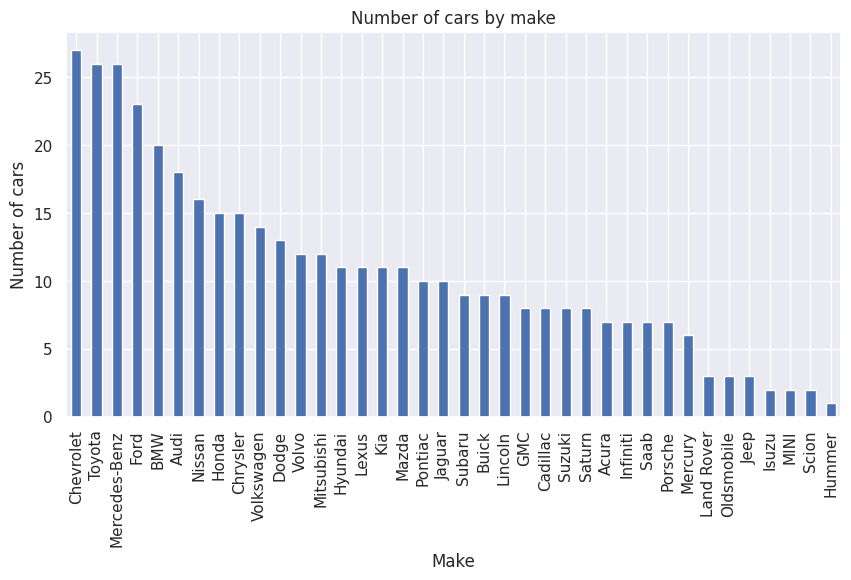

In [ ]:
df.Make.value_counts().nlargest(40).plot(kind='bar', figsize=(10, 5))
plt.title('Number of cars by make')
plt.ylabel('Number of cars')
plt.xlabel('Make')
plt.show()

## Step 14: Scatter plot between the two most related variables (MSRP and Horsepower)

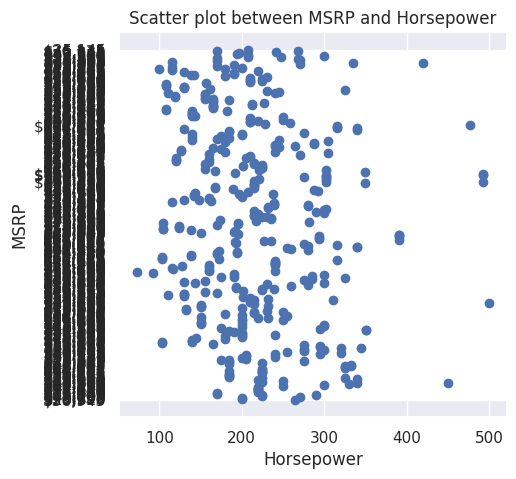

In [ ]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(df['Horsepower'], df['MSRP'])
plt.title('Scatter plot between MSRP and Horsepower')
ax.set_xlabel('Horsepower')
ax.set_ylabel('MSRP')
plt.show()

---
# EXPERIMENT 2: EXPLORATORY DATA ANALYSIS OF THE CALIFORNIA HOUSING DATASET
**Dataset:** `california_housing_train.csv (built into Colab: /content/sample_data/)`

**Aim:** To perform exploratory data analysis on the California Housing dataset: inspect the structure and statistics, study the distribution of the target (median house value), map the housing geography and measure the correlation of every feature with the price.

# EXPERIMENT 2: Exploratory data analysis of the California Housing dataset
## Step 1: Import the required libraries

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns                       # visualisation
import matplotlib.pyplot as plt             # visualisation
%matplotlib inline
sns.set(color_codes=True)

## Step 2: Load the built-in California Housing training dataset
No upload needed - Colab ships this file under `sample_data`.
> If you prefer the Kaggle copy: `kaggle.com/datasets/camnugent/california-housing-prices` -> upload `housing.csv` and set `PATH` to it. Column names are the same except `ocean_proximity` replaces `housing_median_age` ordering.

In [ ]:
PATH = '/content/sample_data/california_housing_train.csv'
df = pd.read_csv(PATH)
print('shape :', df.shape)

shape : (17000, 9)


## Step 3: Display the first 5 rows

In [ ]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-114.31,34.19,15.0,5612.0,1283.0,1015.0,472.0,1.4936,66900.0
1,-114.47,34.40,19.0,7650.0,1901.0,1129.0,463.0,1.8200,80100.0
2,-114.56,33.69,17.0,720.0,174.0,333.0,117.0,1.6509,85700.0
3,-114.57,33.64,14.0,1501.0,337.0,515.0,226.0,3.1917,73400.0
4,-114.57,33.57,20.0,1454.0,326.0,624.0,262.0,1.9250,65500.0


## Step 4: View general information about columns and data types

In [ ]:
print('--- Dataset Information ---')
df.info()

--- Dataset Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17000 entries, 0 to 16999
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           17000 non-null  float64
 1   latitude            17000 non-null  float64
 2   housing_median_age  17000 non-null  float64
 3   total_rooms         17000 non-null  float64
 4   total_bedrooms      17000 non-null  float64
 5   population          17000 non-null  float64
 6   households          17000 non-null  float64
 7   median_income       17000 non-null  float64
 8   median_house_value  17000 non-null  float64
dtypes: float64(9)
memory usage: 1.2 MB


## Step 5: View basic statistics (mean, standard deviation, min, max)

In [ ]:
print('--- Summary Statistics ---')
df.describe()

--- Summary Statistics ---


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000
mean,-119.562108,35.625225,28.589353,2643.664412,539.410824,1429.573941,501.221941,3.883578,207300.912353
std,2.005166,2.137340,12.586937,2179.947071,421.499452,1147.852959,384.520841,1.908157,115983.764387
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.790000,33.930000,18.000000,1462.000000,297.000000,790.000000,282.000000,2.566375,119400.000000
50%,-118.490000,34.250000,29.000000,2127.000000,434.000000,1167.000000,409.000000,3.544600,180400.000000
75%,-118.000000,37.720000,37.000000,3151.250000,648.250000,1721.000000,605.250000,4.767000,265000.000000
max,-114.310000,41.950000,52.000000,37937.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


## Step 6: Analyse the target variable (median house value)
The goal is to understand `median_house_value`, so a histogram shows how prices are distributed.

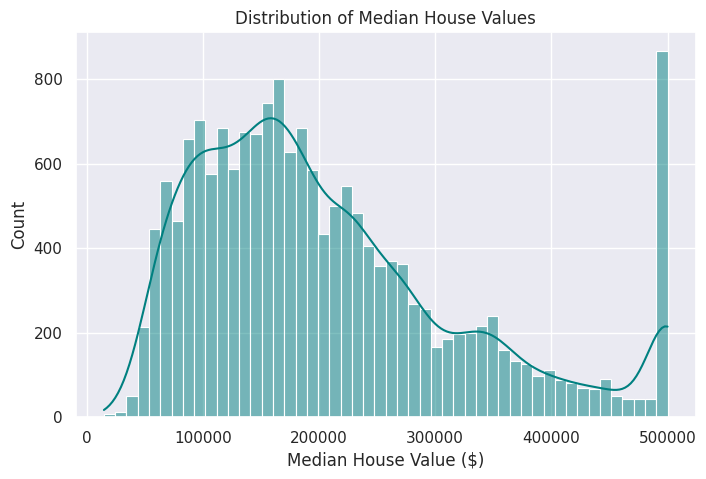

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(df['median_house_value'], bins=50, kde=True, color='teal')
plt.title('Distribution of Median House Values')
plt.xlabel('Median House Value ($)')
plt.ylabel('Count')
plt.show()

## Step 7: Map the housing geography
Longitude and latitude let us recreate the shape of California; colour = house value, size = population.

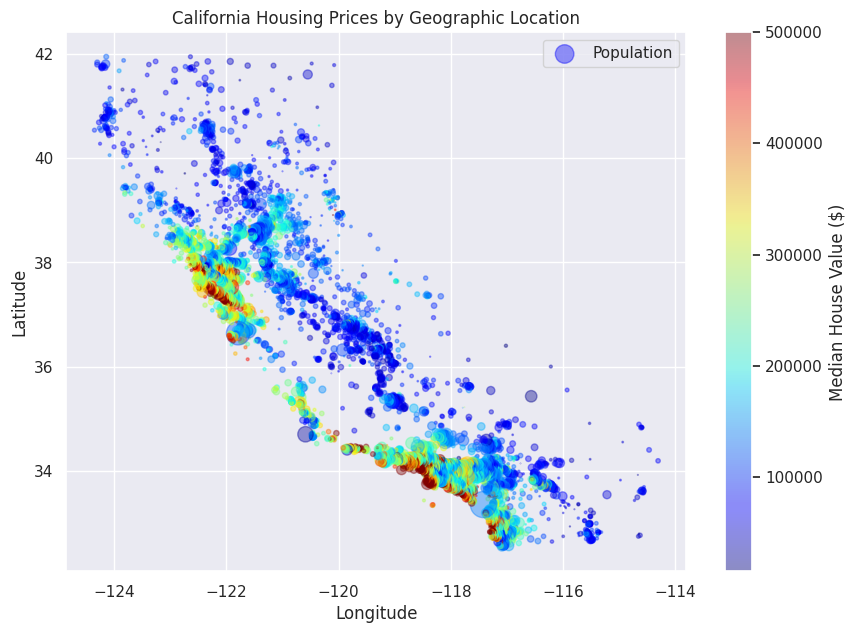

In [ ]:
plt.figure(figsize=(10, 7))
sc = plt.scatter(df['longitude'], df['latitude'], alpha=0.4,
                 s=df['population']/100, label='Population',
                 c=df['median_house_value'], cmap=plt.get_cmap('jet'))
plt.colorbar(sc, label='Median House Value ($)')
plt.title('California Housing Prices by Geographic Location')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.legend()
plt.show()

## Step 8: Check correlations
Features closest to 1.0 have the strongest positive relationship with the price.

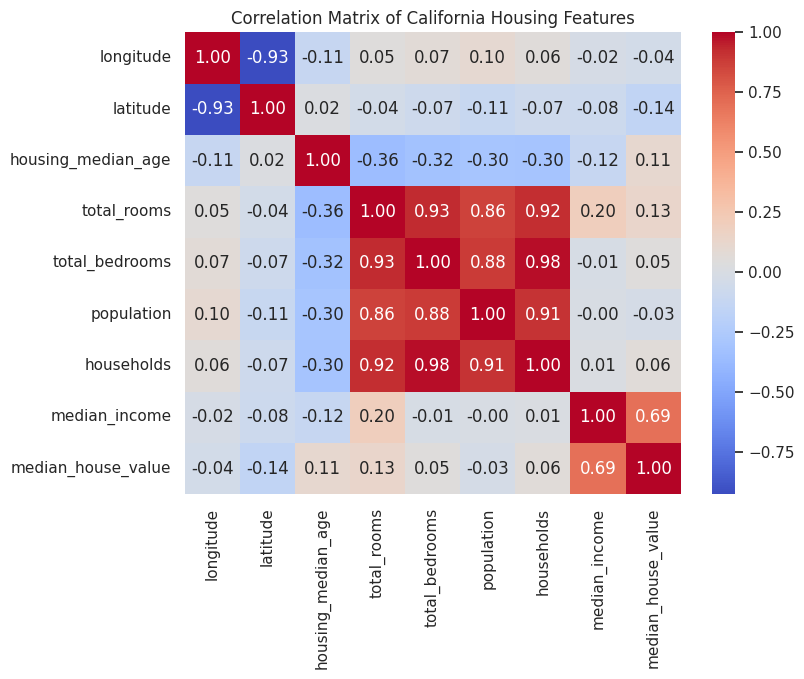

In [ ]:
plt.figure(figsize=(8, 6))
correlation_matrix = df.corr(numeric_only=True)
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of California Housing Features')
plt.show()

In [ ]:
print(correlation_matrix['median_house_value'].sort_values(ascending=False))

median_house_value    1.000000
median_income         0.691871
total_rooms           0.130991
housing_median_age    0.106758
households            0.061031
total_bedrooms        0.045783
population           -0.027850
longitude            -0.044982
latitude             -0.144917
Name: median_house_value, dtype: float64


---
# EXPERIMENT 3: HOTEL BOOKING DATA - EXPLORATORY DATA ANALYSIS (LAB EXERCISE 4)
**Dataset:** `datasetforexp3_hotel_booking.csv  (Kaggle: hotel booking demand)`

**Aim:** To load the hotel booking demand dataset and answer the analysis questions on data quality, cancellations and monthly reservations using pandas groupby, value_counts and filtering.

# EXPERIMENT 3: Hotel booking data - exploratory data analysis (Lab Exercise 4)
## Step 1: Import the required libraries

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns                       # visualisation
import matplotlib.pyplot as plt             # visualisation
%matplotlib inline
sns.set(color_codes=True)
import re
import calendar
sns.set()

## Step 2: Upload and load the data
Upload `datasetforexp3_hotel_booking.csv` to the session storage, then run the cell.
> Kaggle source: `kaggle.com/datasets/jessemostipak/hotel-booking-demand` (`hotel_booking.csv`).

In [ ]:
PATH = '/content/datasetforexp3_hotel_booking.csv'   # replace with your copied path
df = pd.read_csv(PATH)
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,name,email,phone-number,credit_card
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,Transient,0.0,0,0,Check-Out,2015-07-01,Ernest Barnes,Ernest.Barnes31@outlook.com,669-792-1661,************4322
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,Transient,0.0,0,0,Check-Out,2015-07-01,Andrea Baker,Andrea_Baker94@aol.com,858-637-6955,************9157
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,Transient,75.0,0,0,Check-Out,2015-07-02,Rebecca Parker,Rebecca_Parker@comcast.net,652-885-2745,************3734
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,Transient,75.0,0,0,Check-Out,2015-07-02,Laura Murray,Laura_M@gmail.com,364-656-8427,************5677
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,Transient,98.0,0,1,Check-Out,2015-07-03,Linda Hines,LHines@verizon.com,713-226-5883,************5498


## Step 3: Add a unique identifier column
The dataset has no unique key, so we add `id` from the index.

In [ ]:
df = df.reset_index().rename(columns={'index': 'id'})
df.head()

,id,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,...,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,name,email,phone-number,credit_card
0,0,Resort Hotel,0,342,2015,July,27,1,0,0,...,Transient,0.0,0,0,Check-Out,2015-07-01,Ernest Barnes,Ernest.Barnes31@outlook.com,669-792-1661,************4322
1,1,Resort Hotel,0,737,2015,July,27,1,0,0,...,Transient,0.0,0,0,Check-Out,2015-07-01,Andrea Baker,Andrea_Baker94@aol.com,858-637-6955,************9157
2,2,Resort Hotel,0,7,2015,July,27,1,0,1,...,Transient,75.0,0,0,Check-Out,2015-07-02,Rebecca Parker,Rebecca_Parker@comcast.net,652-885-2745,************3734
3,3,Resort Hotel,0,13,2015,July,27,1,0,1,...,Transient,75.0,0,0,Check-Out,2015-07-02,Laura Murray,Laura_M@gmail.com,364-656-8427,************5677
4,4,Resort Hotel,0,14,2015,July,27,1,0,2,...,Transient,98.0,0,1,Check-Out,2015-07-03,Linda Hines,LHines@verizon.com,713-226-5883,************5498


## Step 4 (Question 1): Create a function that checks the datatype, number of null values, percentage of null values and number of unique values for each column

In [ ]:
def check_data(df):
    data = []
    for column in df.columns:
        data.append([column,
                     df[column].dtype,
                     df[column].isna().sum(),
                     round(100 * (df[column].isna().sum() / len(df)), 2),
                     df[column].nunique()])
    return pd.DataFrame(data, columns=['Data_Features', 'Data_Type', 'Null',
                                        'Null_Percentage', 'Unique_Values'])

In [ ]:
check_data(df)

,Data_Features,Data_Type,Null,Null_Percentage,Unique_Values
0,id,int64,0,0.00,119390
1,hotel,object,0,0.00,2
2,is_canceled,int64,0,0.00,2
3,lead_time,int64,0,0.00,479
4,arrival_date_year,int64,0,0.00,3
5,arrival_date_month,object,0,0.00,12
6,arrival_date_week_number,int64,0,0.00,53
7,arrival_date_day_of_month,int64,0,0.00,31
8,stays_in_weekend_nights,int64,0,0.00,17
9,stays_in_week_nights,int64,0,0.00,35


## Step 5 (Question 2a): How many visitors cancel the reservation and how many do not?

In [ ]:
df.is_canceled.value_counts()

,count
is_canceled,
0,75166
1,44224


## Step 6 (Question 2b): Proportion of each value

In [ ]:
df.is_canceled.value_counts(normalize=True)

,proportion
is_canceled,
0,0.629584
1,0.370416


## Step 7 (Question 2c): Visualise the counts with a countplot

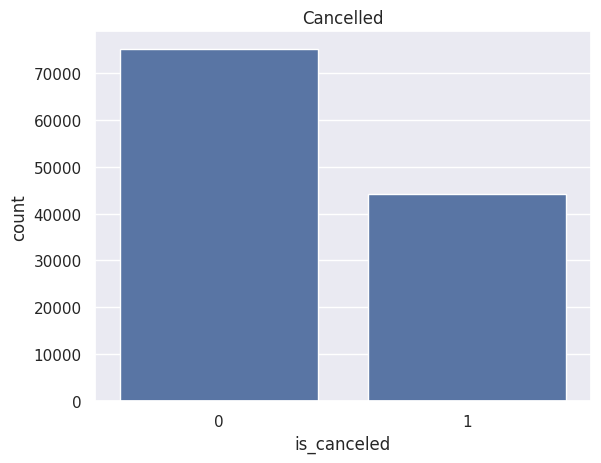

In [ ]:
sns.countplot(data=df, x='is_canceled')
plt.title('Cancelled')
plt.show()

## Step 8 (Question 3a): For "City Hotel", what is the percentage of cancelled reservations?

In [ ]:
city = round(100 * (len(df[(df.hotel == 'City Hotel') & (df.is_canceled == 1)])
                      / len(df[df.hotel == 'City Hotel'])), 2)
print('City Hotel cancellation % :', city)

City Hotel cancellation % : 41.73


## Step 9 (Question 3b): For "Resort Hotel", what is the percentage of cancelled reservations?

In [ ]:
resort = round(100 * (len(df[(df.hotel == 'Resort Hotel') & (df.is_canceled == 1)])
                        / len(df[df.hotel == 'Resort Hotel'])), 2)
print('Resort Hotel cancellation % :', resort)

Resort Hotel cancellation % : 27.76


## Step 10 (Question 3c): Which hotel type has the bigger percentage of cancellations?

In [ ]:
print('Bigger cancellation percentage :', 'City Hotel' if city > resort else 'Resort Hotel')
print(f'City = {city}%   Resort = {resort}%')

Bigger cancellation percentage : City Hotel
City = 41.73%   Resort = 27.76%


## Step 11 (Question 4): Filter the visitors who did NOT cancel, store them in df_checkout

In [ ]:
df_checkout = df[df.is_canceled == 0]
print('df_checkout shape :', df_checkout.shape)

df_checkout shape : (75166, 37)


In [ ]:
df_checkout.head()

,id,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,...,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,name,email,phone-number,credit_card
0,0,Resort Hotel,0,342,2015,July,27,1,0,0,...,Transient,0.0,0,0,Check-Out,2015-07-01,Ernest Barnes,Ernest.Barnes31@outlook.com,669-792-1661,************4322
1,1,Resort Hotel,0,737,2015,July,27,1,0,0,...,Transient,0.0,0,0,Check-Out,2015-07-01,Andrea Baker,Andrea_Baker94@aol.com,858-637-6955,************9157
2,2,Resort Hotel,0,7,2015,July,27,1,0,1,...,Transient,75.0,0,0,Check-Out,2015-07-02,Rebecca Parker,Rebecca_Parker@comcast.net,652-885-2745,************3734
3,3,Resort Hotel,0,13,2015,July,27,1,0,1,...,Transient,75.0,0,0,Check-Out,2015-07-02,Laura Murray,Laura_M@gmail.com,364-656-8427,************5677
4,4,Resort Hotel,0,14,2015,July,27,1,0,2,...,Transient,98.0,0,1,Check-Out,2015-07-03,Linda Hines,LHines@verizon.com,713-226-5883,************5498


## Step 12 (Question 5a): Number of reservations per month of arrival for each hotel type

In [ ]:
df_checkout.groupby(['hotel', 'arrival_date_month']).size()

hotel         arrival_date_month
City Hotel    April                 4015
              August                5381
              December              2392
              February              3064
              January               2254
              July                  4782
              June                  4366
              March                 4072
              May                   4579
              November              2696
              October               4337
              September             4290
Resort Hotel  April                 2550
              August                3257
              December              2017
              February              2308
              January               1868
              July                  3137
              June                  2038
              March                 2573
              May                   2535
              November              1976
              October               2577
              September             2102
dtype: int64

## Step 13 (Question 5b): Map the month names to month numbers

In [ ]:
month_dict = {month: index for index, month in enumerate(calendar.month_name) if month}
df_checkout['arrival_date_month_num'] = df_checkout['arrival_date_month'].map(month_dict)
df_checkout.groupby(['hotel', 'arrival_date_month_num']).size()

/tmp/ipykernel_665/4026382264.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_checkout['arrival_date_month_num'] = df_checkout['arrival_date_month'].map(month_dict)


hotel         arrival_date_month_num
City Hotel    1                         2254
              2                         3064
              3                         4072
              4                         4015
              5                         4579
              6                         4366
              7                         4782
              8                         5381
              9                         4290
              10                        4337
              11                        2696
              12                        2392
Resort Hotel  1                         1868
              2                         2308
              3                         2573
              4                         2550
              5                         2535
              6                         2038
              7                         3137
              8                         3257
              9                         2102
              10                        2577
              11                        1976
              12                        2017
dtype: int64

---
# EXPERIMENT 4: TIME SERIES ANALYSIS OF THE DAILY CLIMATE DATASET
**Dataset:** `DailyDelhiClimateTrain.csv (Kaggle: daily-climate-time-series-data)`

**Aim:** To load the daily climate time series, make it a proper datetime-indexed series with a daily frequency, plot its metrics and perform a rolling-window (moving average) analysis.

# EXPERIMENT 4: Time series analysis of the daily climate dataset
## Step 1: Initialise libraries and load the data
> Kaggle: `kaggle.com/datasets/sumanthvrao/daily-climate-time-series-data` -> upload `DailyDelhiClimateTrain.csv`.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
sns.set()

# Download the required dataset from Kaggle
!pip install -q kaggle
!kaggle datasets download -d sumanthvrao/daily-climate-time-series-data
!unzip -o daily-climate-time-series-data.zip

PATH = 'DailyDelhiClimateTrain.csv'
df = pd.read_csv(PATH)
df.head()

Dataset URL: https://www.kaggle.com/datasets/sumanthvrao/daily-climate-time-series-data
License(s): CC0-1.0
daily-climate-time-series-data.zip: Skipping, found more recently modified local copy (use --force to force download)
Archive:  daily-climate-time-series-data.zip
  inflating: DailyDelhiClimateTest.csv  
  inflating: DailyDelhiClimateTrain.csv  


,date,meantemp,humidity,wind_speed,meanpressure
0,2013-01-01,10.000000,84.500000,0.000000,1015.666667
1,2013-01-02,7.400000,92.000000,2.980000,1017.800000
2,2013-01-03,7.166667,87.000000,4.633333,1018.666667
3,2013-01-04,8.666667,71.333333,1.233333,1017.166667
4,2013-01-05,6.000000,86.833333,3.700000,1016.500000


## Step 2: Convert 'date' to datetime and set it as the index

In [ ]:
df['date'] = pd.to_datetime(df['date'])
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1462 entries, 0 to 1461
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   date          1462 non-null   datetime64[ns]
 1   meantemp      1462 non-null   float64       
 2   humidity      1462 non-null   float64       
 3   wind_speed    1462 non-null   float64       
 4   meanpressure  1462 non-null   float64       
dtypes: datetime64[ns](1), float64(4)
memory usage: 57.2 KB


In [ ]:
df = df.set_index('date').sort_index()
df.head()

,meantemp,humidity,wind_speed,meanpressure
date,,,,
2013-01-01,10.000000,84.500000,0.000000,1015.666667
2013-01-02,7.400000,92.000000,2.980000,1017.800000
2013-01-03,7.166667,87.000000,4.633333,1018.666667
2013-01-04,8.666667,71.333333,1.233333,1017.166667
2013-01-05,6.000000,86.833333,3.700000,1016.500000


## Step 3: Explicitly set the frequency to 'D' (Daily) and check missing values
`asfreq('D')` rebuilds a complete calendar so gaps become visible as NaN.

In [ ]:
df = df.asfreq('D')
print('Frequency :', df.index.freq)
print('\nMissing values created by fixing the gaps:')
print(df.isna().sum())

Frequency : <Day>

Missing values created by fixing the gaps:
meantemp        0
humidity        0
wind_speed      0
meanpressure    0
dtype: int64


## Step 4: Plot the mean temperature

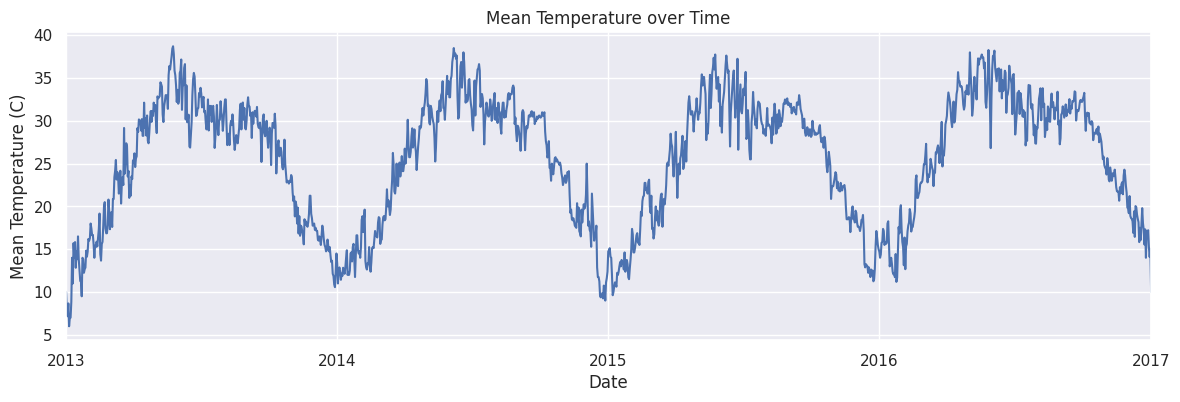

In [ ]:
plt.figure(figsize=(14, 4))
df['meantemp'].plot()
plt.title('Mean Temperature over Time')
plt.xlabel('Date')
plt.ylabel('Mean Temperature (C)')
plt.show()

## Step 5: Plot the humidity

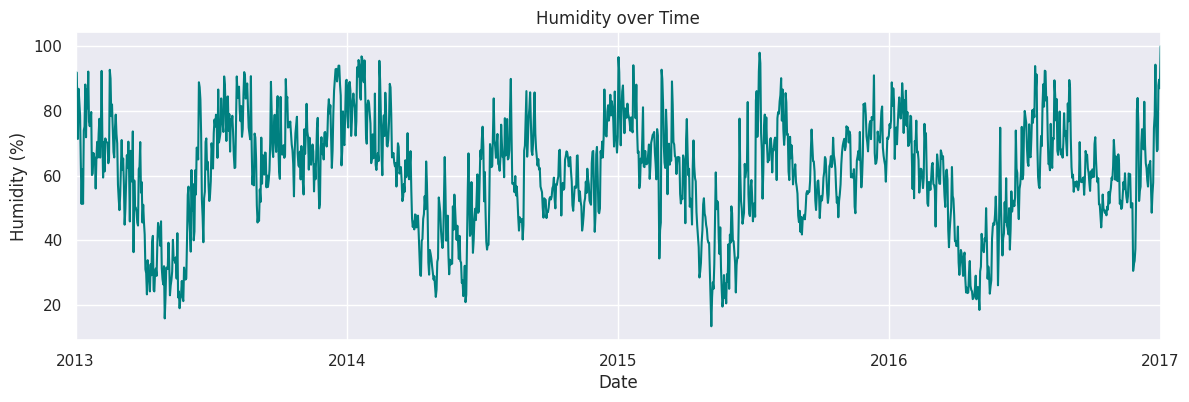

In [ ]:
plt.figure(figsize=(14, 4))
df['humidity'].plot(color='teal')
plt.title('Humidity over Time')
plt.xlabel('Date')
plt.ylabel('Humidity (%)')
plt.show()

## Step 6: Plot the wind speed

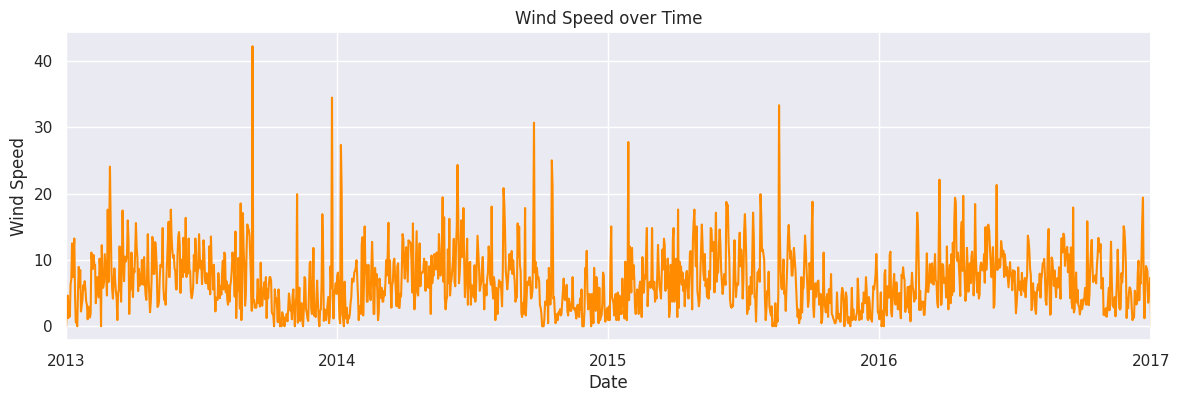

In [ ]:
plt.figure(figsize=(14, 4))
df['wind_speed'].plot(color='darkorange')
plt.title('Wind Speed over Time')
plt.xlabel('Date')
plt.ylabel('Wind Speed')
plt.show()

## Step 7: Plot the mean pressure

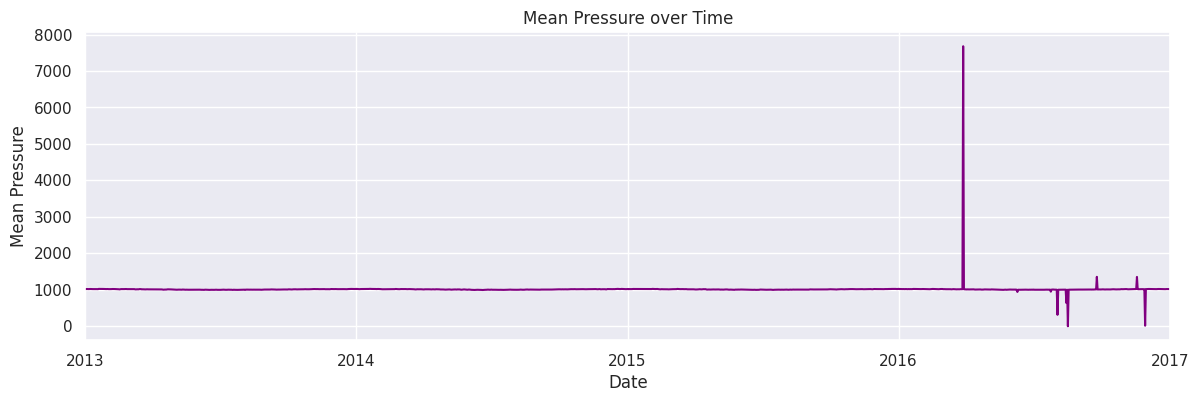

In [ ]:
plt.figure(figsize=(14, 4))
df['meanpressure'].plot(color='purple')
plt.title('Mean Pressure over Time')
plt.xlabel('Date')
plt.ylabel('Mean Pressure')
plt.show()

## Step 8: Rolling window analysis - actual temperature, 7-day MA and 14-day MA
`rolling(window).mean()` puts the average of the last `window` days at each point.

In [ ]:
df['temp_7d_MA']  = df['meantemp'].rolling(window=7).mean()
df['temp_14d_MA'] = df['meantemp'].rolling(window=14).mean()
print(df[['meantemp', 'temp_7d_MA', 'temp_14d_MA']].head(20))

             meantemp  temp_7d_MA  temp_14d_MA
date                                          
2013-01-01  10.000000         NaN          NaN
2013-01-02   7.400000         NaN          NaN
2013-01-03   7.166667         NaN          NaN
2013-01-04   8.666667         NaN          NaN
2013-01-05   6.000000         NaN          NaN
2013-01-06   7.000000         NaN          NaN
2013-01-07   7.000000    7.604762          NaN
2013-01-08   8.857143    7.441497          NaN
2013-01-09  14.000000    8.384354          NaN
2013-01-10  11.000000    8.931973          NaN
2013-01-11  15.714286    9.938776          NaN
2013-01-12  14.000000   11.081633          NaN
2013-01-13  15.833333   12.343537          NaN
2013-01-14  12.833333   13.176871    10.390816
2013-01-15  14.714286   14.013605    10.727551
2013-01-16  13.833333   13.989796    11.187075
2013-01-17  16.500000   14.775510    11.853741
2013-01-18  13.833333   14.506803    12.222789
2013-01-19  12.500000   14.292517    12.687075
2013-01-20  1

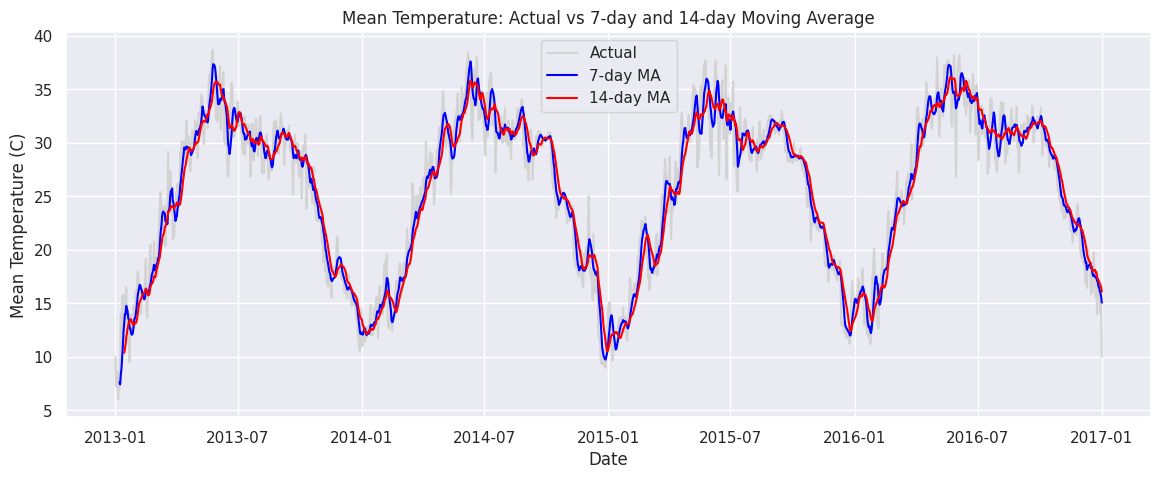

In [ ]:
plt.figure(figsize=(14, 5))
plt.plot(df.index, df['meantemp'],   label='Actual',      color='lightgrey')
plt.plot(df.index, df['temp_7d_MA'],  label='7-day MA',    color='blue')
plt.plot(df.index, df['temp_14d_MA'], label='14-day MA',   color='red')
plt.title('Mean Temperature: Actual vs 7-day and 14-day Moving Average')
plt.xlabel('Date')
plt.ylabel('Mean Temperature (C)')
plt.legend()
plt.show()

## Step 9: Confirm the series is a proper daily period index and view a monthly summary

In [ ]:
print('PeriodIndex? :', isinstance(df.index, pd.PeriodIndex) or bool(df.index.freq))
print('Start / End :', df.index.min(), '/', df.index.max())
df['meantemp'].resample('ME').mean().round(2)

PeriodIndex? : True
Start / End : 2013-01-01 00:00:00 / 2017-01-01 00:00:00


,meantemp
date,
2013-01-31,12.07
2013-02-28,16.87
2013-03-31,22.81
2013-04-30,28.90
2013-05-31,33.78
2013-06-30,32.48
2013-07-31,30.66
2013-08-31,29.55
2013-09-30,29.84


---
# EXPERIMENT 5: TIME SERIES DECOMPOSITION TECHNIQUES
**Dataset:** `synthetic series (generated in the notebook, no CSV)`

**Aim:** To implement multiple time series decomposition techniques - additive decomposition, trend and seasonal plots, simple moving average (SMA) and exponential moving average (EMA) - on a synthetic time series dataset.

# EXPERIMENT 5: Time series decomposition techniques
## Step 1: Import the required libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.holtwinters import ExponentialSmoothing
%matplotlib inline
sns.set()

## Step 2: Create a synthetic time series dataset
Trend + a 12-month seasonal pattern + random noise, sampled daily for 3 years.

In [ ]:
np.random.seed(42)
n = 365 * 3
dates = pd.date_range(start='2022-01-01', periods=n, freq='D')

trend    = np.linspace(50, 80, n)                        # slow upward trend
seasonal = 10 * np.sin(2 * np.pi * np.arange(n) / 365)  # yearly cycle
noise    = np.random.normal(0, 3, n)                     # random fluctuation

ts = pd.Series(trend + seasonal + noise, index=dates, name='value')
ts.head()

,value
2022-01-01,51.490142
2022-01-02,49.784763
2022-01-03,52.342126
2022-01-04,55.167553
2022-01-05,50.095253


## Step 3: Visualise the time series

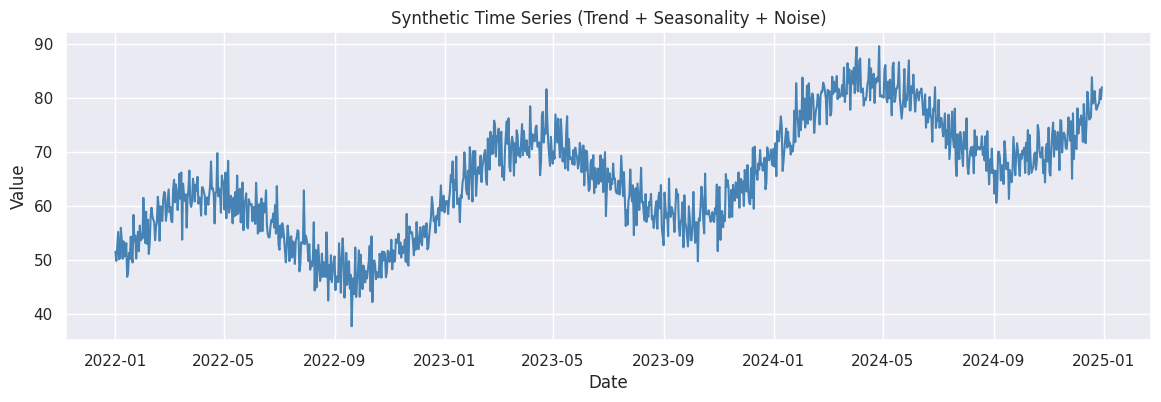

In [ ]:
plt.figure(figsize=(14, 4))
plt.plot(ts.index, ts.values, color='steelblue')
plt.title('Synthetic Time Series (Trend + Seasonality + Noise)')
plt.xlabel('Date')
plt.ylabel('Value')
plt.show()

## Step 4: Apply additive decomposition
`period=365` because the cycle is yearly; `model='additive'` because the seasonal amplitude is constant.

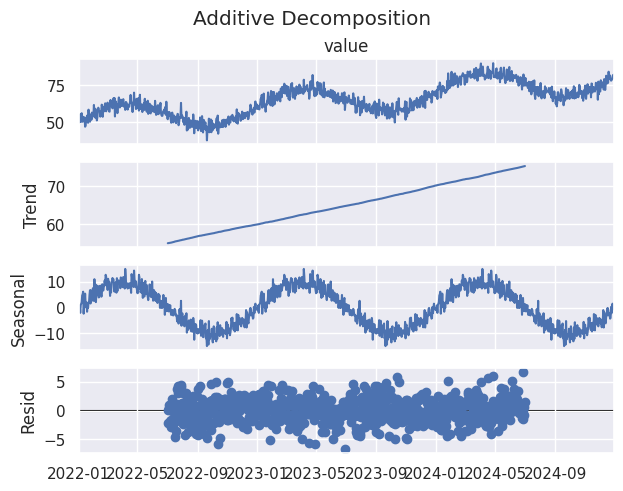

In [ ]:
decomposition = seasonal_decompose(ts, model='additive', period=365)
decomposition.plot()
plt.suptitle('Additive Decomposition', y=1.02)
plt.show()

## Step 5: Plot the trend component

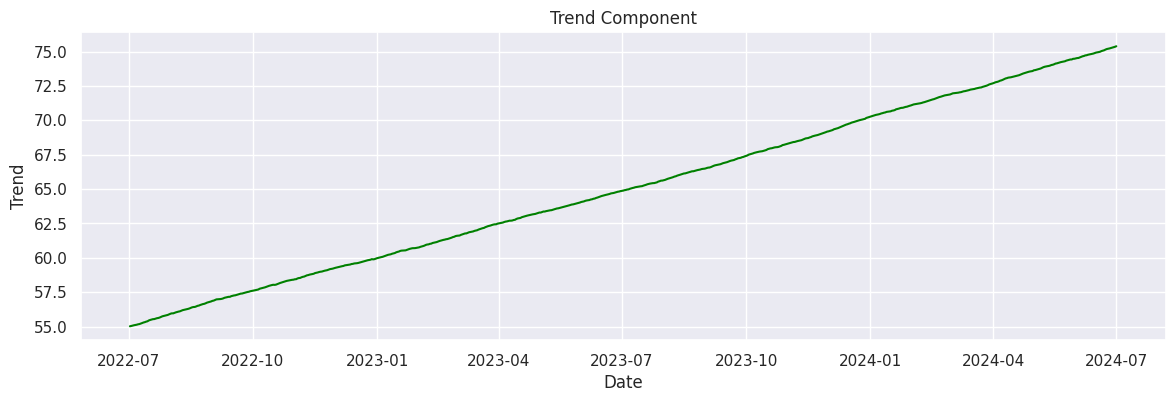

In [ ]:
plt.figure(figsize=(14, 4))
plt.plot(decomposition.trend, color='green')
plt.title('Trend Component')
plt.xlabel('Date')
plt.ylabel('Trend')
plt.show()

## Step 6: Plot the seasonal component

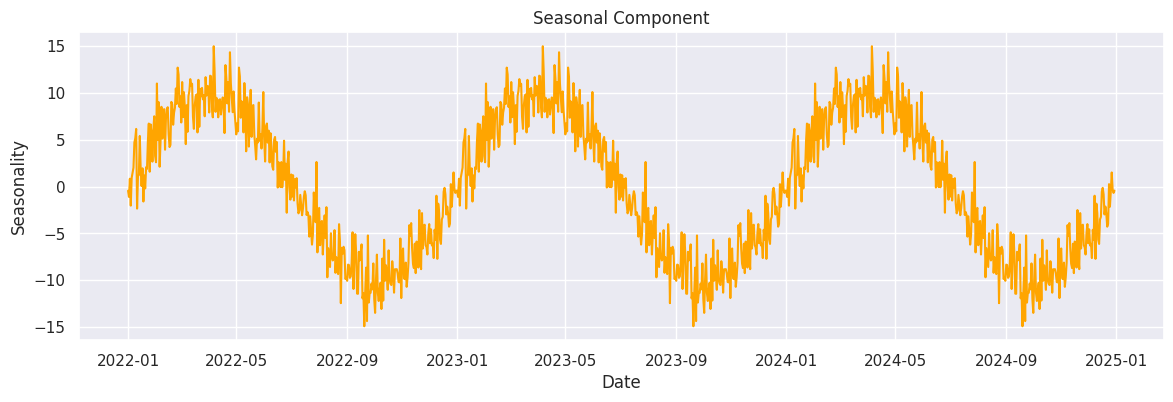

In [ ]:
plt.figure(figsize=(14, 4))
plt.plot(decomposition.seasonal, color='orange')
plt.title('Seasonal Component')
plt.xlabel('Date')
plt.ylabel('Seasonality')
plt.show()

In [ ]:
print('Residual statistics:')
print(decomposition.resid.describe())

Residual statistics:
count    731.000000
mean       0.034006
std        2.084491
min       -6.689148
25%       -1.317842
50%        0.039451
75%        1.385855
max        6.757161
Name: resid, dtype: float64


## Step 7: Calculate the simple moving average (SMA)

In [ ]:
window = 30
ts_sma = ts.rolling(window=window).mean()
print(f'{window}-day SMA (first 40 rows):')
ts_sma.head(40)

30-day SMA (first 40 rows):


,value
2022-01-01,NaN
2022-01-02,NaN
2022-01-03,NaN
2022-01-04,NaN
2022-01-05,NaN
2022-01-06,NaN
2022-01-07,NaN
2022-01-08,NaN
2022-01-09,NaN
2022-01-10,NaN


## Step 8: Calculate the exponential moving average (EMA)

In [ ]:
alpha = 0.1   # smoothing factor
ts_ema = ts.ewm(alpha=alpha, adjust=False).mean()
print(f'EMA with alpha = {alpha} (first 40 rows):')
ts_ema.head(40)

EMA with alpha = 0.1 (first 40 rows):


,value
2022-01-01,51.490142
2022-01-02,51.319605
2022-01-03,51.421857
2022-01-04,51.796426
2022-01-05,51.626309
2022-01-06,51.493113
2022-01-07,51.937121
2022-01-08,52.113043
2022-01-09,51.920113
2022-01-10,52.069858


## Step 9: Plot the moving averages

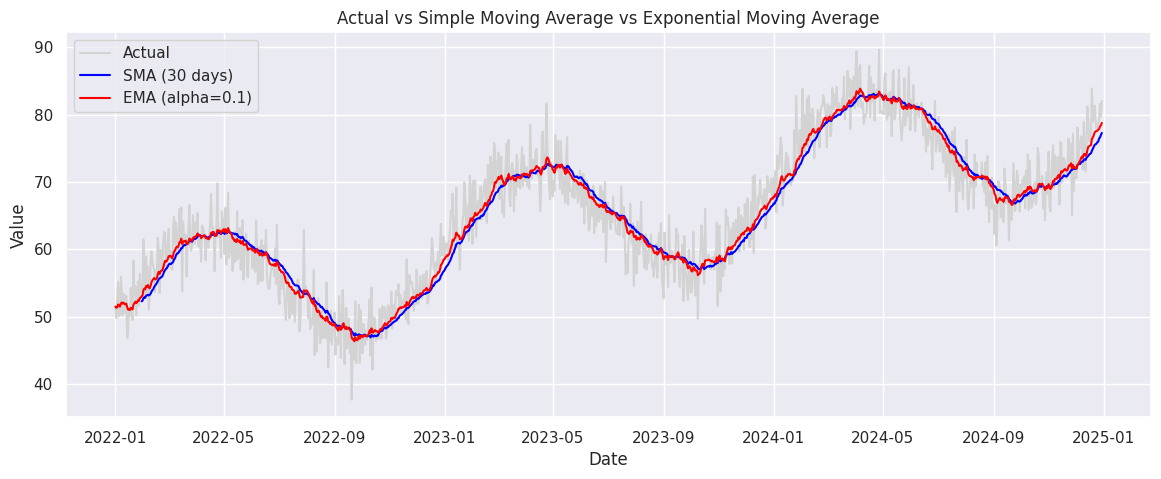

In [ ]:
plt.figure(figsize=(14, 5))
plt.plot(ts.index, ts.values,      label='Actual',          color='lightgrey')
plt.plot(ts_sma.index, ts_sma.values, label=f'SMA ({window} days)', color='blue')
plt.plot(ts_ema.index, ts_ema.values, label=f'EMA (alpha={alpha})', color='red')
plt.title('Actual vs Simple Moving Average vs Exponential Moving Average')
plt.xlabel('Date')
plt.ylabel('Value')
plt.legend()
plt.show()

---
# EXPERIMENT 6: LINEAR REGRESSION
**Dataset:** `datasetforexp6_salary.csv  (columns: age, salary)`

**Aim:** To implement simple linear regression with scikit-learn on a random dataset, to plot the best-fit line and report the slope and intercept, and then to use the attached salary dataset to predict an employee's salary from their age.

# EXPERIMENT 6: Linear Regression
## Step 1: Import the necessary libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
%matplotlib inline
sns.set()

## Step 2: Generate a random dataset

In [ ]:
np.random.seed(42)
X = np.random.rand(50, 1) * 100
Y = 3.5 * X + np.random.randn(50, 1) * 20
print(X.shape, Y.shape)

(50, 1) (50, 1)


## Step 3: Create and train the linear regression model

In [ ]:
model = LinearRegression()
model.fit(X, Y)

LinearRegression()

## Step 4: Predict the Y values

In [ ]:
Y_pred = model.predict(X)
Y_pred[:5]

array([[131.34912718],
       [330.4353548 ],
       [254.86061849],
       [208.78904181],
       [ 55.84311228]])

## Step 5: Visualise the regression line

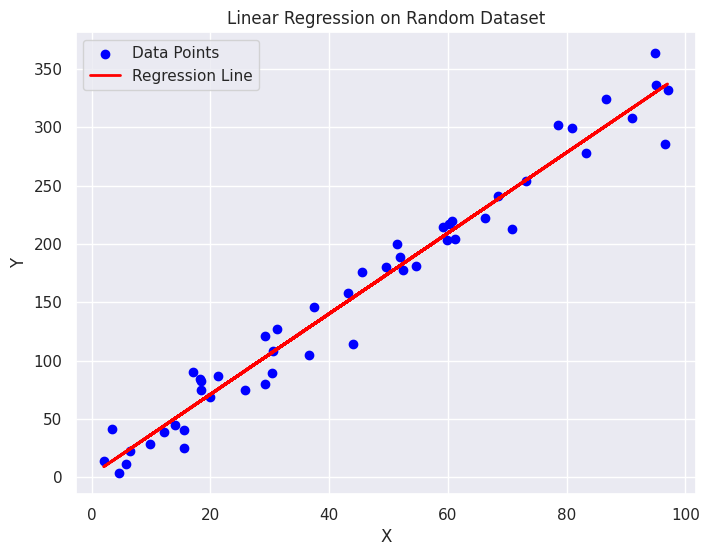

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(X, Y, color='blue', label='Data Points')
plt.plot(X, Y_pred, color='red', linewidth=2, label='Regression Line')
plt.title('Linear Regression on Random Dataset')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.grid(True)
plt.show()

## Step 6: Print the slope and intercept

In [ ]:
print('Slope (Coefficient):', model.coef_[0][0])
print('Intercept:', model.intercept_[0])

Slope (Coefficient): 3.4553132007706204
Intercept: 1.9337854893777546


## Step 7 (Exercise): Load the attached salary dataset
Upload `datasetforexp6_salary.csv` (columns `age`, `salary`).

In [ ]:
PATH = '/content/datasetforexp6_salary.csv'   # replace with your copied path
df = pd.read_csv(PATH)
df.head()

,age,salary
0,20,50000
1,22,55000
2,24,60000
3,25,62000
4,30,70000


In [ ]:
print('shape :', df.shape)
df.describe()

shape : (22, 2)


,age,salary
count,22.000000,22.000000
mean,58.136364,149863.636364
std,25.321355,65852.863014
min,20.000000,50000.000000
25%,36.250000,85000.000000
50%,58.500000,160000.000000
75%,78.750000,197500.000000
max,100.000000,260000.000000


## Step 8 (Exercise): Visualise age vs salary to confirm a linear relationship

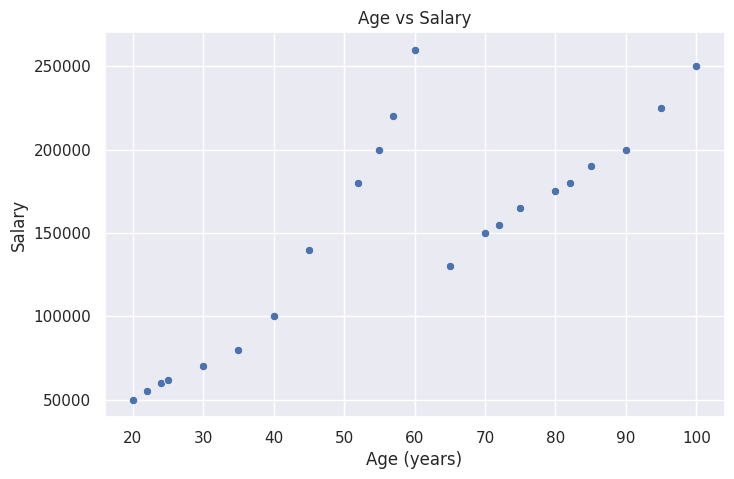

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='age', y='salary')
plt.title('Age vs Salary')
plt.xlabel('Age (years)')
plt.ylabel('Salary')
plt.show()

## Step 9 (Exercise): Fit the linear regression and plot the best-fit line

In [ ]:
X_sal = df[['age']]
y_sal = df['salary']

sal_model = LinearRegression()
sal_model.fit(X_sal, y_sal)
y_sal_pred = sal_model.predict(X_sal)

print('Slope (Coefficient):', sal_model.coef_[0])
print('Intercept:', sal_model.intercept_)

Slope (Coefficient): 2153.3821032269825
Intercept: 24673.831362394965


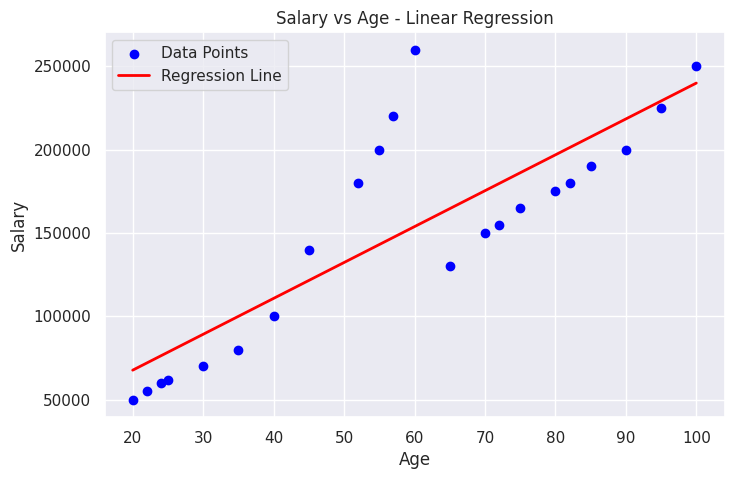

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(df['age'], df['salary'], color='blue', label='Data Points')
plt.plot(df['age'], y_sal_pred, color='red', linewidth=2, label='Regression Line')
plt.title('Salary vs Age - Linear Regression')
plt.xlabel('Age')
plt.ylabel('Salary')
plt.legend()
plt.grid(True)
plt.show()

## Step 10 (Exercise): Predict the salary of an employee after entering his age

In [ ]:
age = int(input('Enter the age of the employee: '))
predicted_salary = sal_model.predict([[age]])[0]
print(f'Predicted salary for age {age} : {predicted_salary:,.2f}')

Enter the age of the employee: 20
Predicted salary for age 20 : 67,741.47


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [ ]:
# Same model applied to a range of ages
ages = pd.DataFrame({'age': [25, 30, 40, 50, 60]})
ages['predicted_salary'] = sal_model.predict(ages[['age']]).round(2)
ages

,age,predicted_salary
0,25,78508.38
1,30,89275.29
2,40,110809.12
3,50,132342.94
4,60,153876.76


---
# EXPERIMENT 7: K-NEAREST NEIGHBOURS (KNN) CLASSIFICATION
**Dataset:** `inline dictionary (Age, Income, Bought) - no CSV needed`

**Aim:** To implement the K-Nearest Neighbours algorithm for classification, to show how the value of K changes the prediction of a new point, and to predict whether a customer bought the product using Age and Income.

# EXPERIMENT 7: K-Nearest Neighbours (KNN) classification
## Step 1: Visualise the sample data points

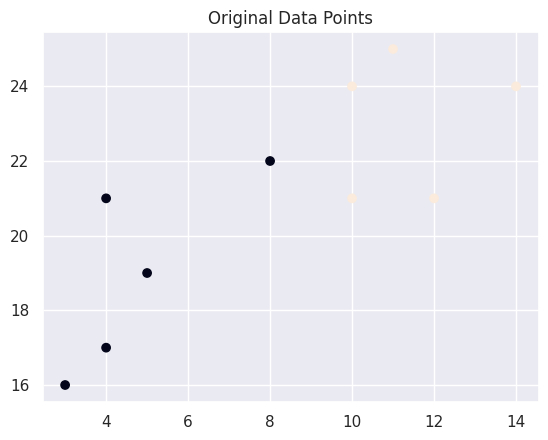

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
%matplotlib inline

x = [4, 5, 10, 4, 3, 11, 14, 8, 10, 12]
y = [21, 19, 24, 17, 16, 25, 24, 22, 21, 21]
classes = [0, 0, 1, 0, 0, 1, 1, 0, 1, 1]

plt.scatter(x, y, c=classes)
plt.title('Original Data Points')
plt.show()

## Step 2: Fit the KNN algorithm with K = 1

In [ ]:
data = list(zip(x, y))
knn = KNeighborsClassifier(n_neighbors=1)
knn.fit(data, classes)

KNeighborsClassifier(n_neighbors=1)

## Step 3: Classify the new point with K = 1

In [ ]:
new_x = 8
new_y = 21
new_point = [(new_x, new_y)]

prediction = knn.predict(new_point)
print('Prediction with K = 1 :', prediction[0])

Prediction with K = 1 : 0


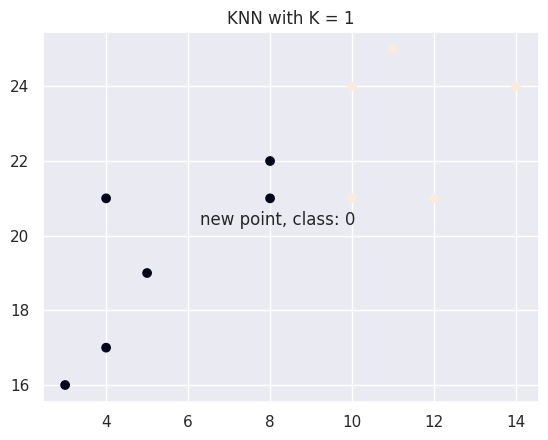

In [ ]:
plt.scatter(x + [new_x], y + [new_y], c=classes + [prediction[0]])
plt.text(x=new_x - 1.7, y=new_y - 0.7, s=f'new point, class: {prediction[0]}')
plt.title('KNN with K = 1')
plt.show()

## Step 4: Repeat with K = 5 - the prediction changes

In [ ]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(data, classes)
prediction = knn.predict(new_point)
print('Prediction with K = 5 :', prediction[0])

Prediction with K = 5 : 1


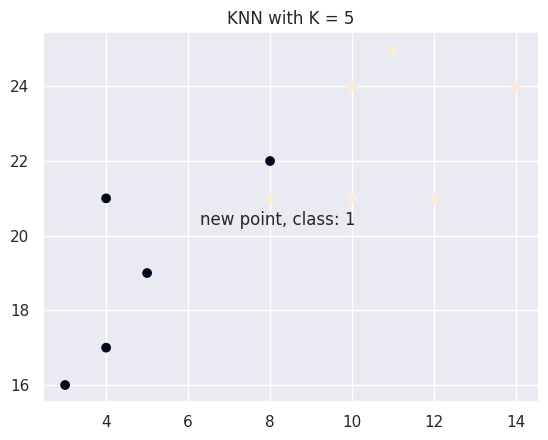

In [ ]:
plt.scatter(x + [new_x], y + [new_y], c=classes + [prediction[0]])
plt.text(x=new_x - 1.7, y=new_y - 0.7, s=f'new point, class: {prediction[0]}')
plt.title('KNN with K = 5')
plt.show()

## Step 5 (Exercise): Build the customer dataset from the attached data

In [ ]:
data = {'Age':    [25, 35, 45, 20, 55, 60, 40, 22, 29, 50, 52, 23, 31, 44, 39],
        'Income': [40, 60, 80, 20, 120, 140, 90, 25, 50, 110, 115, 30, 70, 85, 75],
        'Bought': [0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0]}

df = pd.DataFrame(data)
df

,Age,Income,Bought
0,25,40,0
1,35,60,0
2,45,80,1
3,20,20,0
4,55,120,1
5,60,140,1
6,40,90,1
7,22,25,0
8,29,50,0
9,50,110,1


## Step 6 (Exercise): Visualise the customers by their label

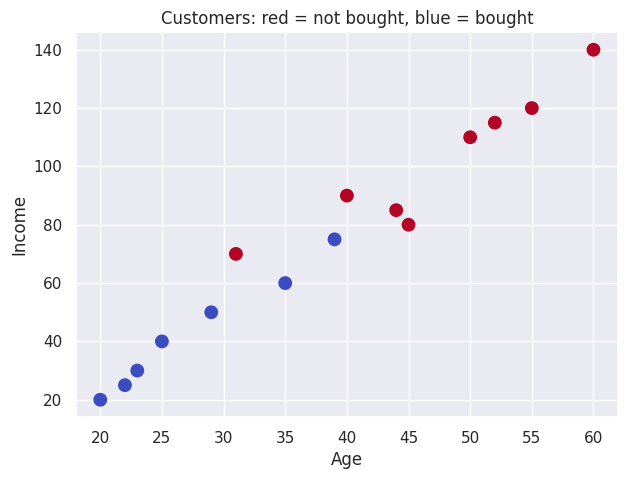

In [ ]:
plt.figure(figsize=(7, 5))
plt.scatter(df['Age'], df['Income'], c=df['Bought'], cmap='coolwarm', s=80)
plt.title('Customers: red = not bought, blue = bought')
plt.xlabel('Age')
plt.ylabel('Income')
plt.show()

## Step 7 (Exercise): Predict whether a customer bought the product using Age and Income

In [ ]:
X = df[['Age', 'Income']]
y = df['Bought']

knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X, y)

new_customers = pd.DataFrame({'Age': [30, 45, 55], 'Income': [50, 95, 130]})
new_customers['Bought_Predicted'] = knn.predict(new_customers[['Age', 'Income']])
new_customers

,Age,Income,Bought_Predicted
0,30,50,0
1,45,95,1
2,55,130,1


## Step 8 (Exercise): Check the accuracy on a held-out split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
knn_eval = KNeighborsClassifier(n_neighbors=3).fit(X_train, y_train)
print('Accuracy :', accuracy_score(y_test, knn_eval.predict(X_test)))

Accuracy : 1.0


## Step 9 (Exercise): Plot the decision boundary for K = 3

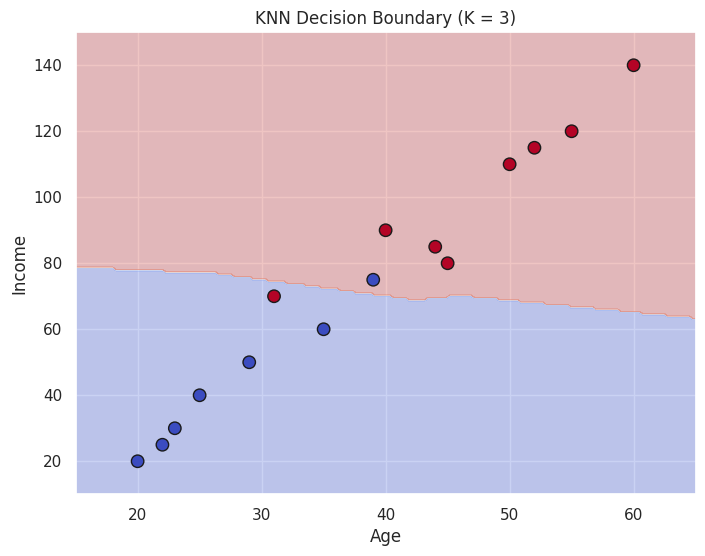

In [ ]:
knn_full = KNeighborsClassifier(n_neighbors=3).fit(X, y)

ages = np.linspace(df['Age'].min() - 5, df['Age'].max() + 5, 200)
incomes = np.linspace(df['Income'].min() - 10, df['Income'].max() + 10, 200)
xx, yy = np.meshgrid(ages, incomes)
grid = pd.DataFrame({'Age': xx.ravel(), 'Income': yy.ravel()})
Z = knn_full.predict(grid).reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
plt.scatter(df['Age'], df['Income'], c=df['Bought'], cmap='coolwarm', edgecolor='k', s=80)
plt.title('KNN Decision Boundary (K = 3)')
plt.xlabel('Age')
plt.ylabel('Income')
plt.show()